# Experiment 4: Fixing 4 bit for Dr Li's LLE (quantisation aware training and distillation)
**Forhad Islam.** Trained on my RTX 3090 on 17 October.

Plain 4 bit broke the LLE (Experiment 3A). Here I fix it:
* **Part 1, v1:** quantisation aware training (QAT). Every layer is rounded to 4 bit during training, and gradients pass straight through the rounding. The training data is made the way his Matlab generator does it.
* **Part 2, V2 to V4:** V2 adds **distillation** from his full precision LLE plus data matched to his images, V3 adds **learned scales**, V4 keeps **four tiny layers at 8 bit**.

| Version | Size | Synthetic images | Real HEK293 cells |
|---|---|---|---|
| His original (32 bit) | 107 KB | 0.161 ns | 0.134 ns |
| Plain 4 bit | 13 KB | 1.47 ns (broken) | 1.04 ns (broken) |
| v1 | 13 KB | 0.259 ns | 0.185 ns |
| **V4** | **13.5 KB** | **0.167 ns** | **0.142 ns** |

**RETRAIN switch:** training takes about 35 minutes. With `RETRAIN = False` (default), the notebook shows all the training code but **scores the 4 bit models my GPU already trained**. Set `RETRAIN = True` to train again (this overwrites the saved models).

In [1]:
import os, sys, glob, subprocess, warnings
warnings.filterwarnings("ignore")
HERE = os.getcwd()                                                       # this experiment's folder
BASE = HERE                                                          # find the University of Strathclyde folder (works at any depth)
while not os.path.isdir(os.path.join(BASE, "04_Shared_Code_and_Data")) and os.path.dirname(BASE) != BASE:
    BASE = os.path.dirname(BASE)
CODE = os.path.join(BASE, "04_Shared_Code_and_Data", "Dr_Li_FPFLI_code")  # Dr Li's FPFLI code, models and sample data
DATA = os.path.join(BASE, "04_Shared_Code_and_Data", "Datasets")
GLASGOW = os.path.join(DATA, "SPAD_FLIM_Glasgow_Zickus2020",
    "DATA_REPOSITORY_fluorescence_lifetime_imaging_with_a_megapixel_SPAD_camera_and_neural_network_lifetime_estimation")
try:
    import mat73
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "mat73"], check=True); import mat73
sys.path.insert(0, CODE); os.chdir(CODE)     # Dr Li's code uses paths like sample_data/... and ./model_parameters/...
import torch
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NONE")
print("results will be saved in:", HERE)

RETRAIN = False   # True = train again on the GPU (about 35 minutes, overwrites the saved 4 bit models)

GPU: NVIDIA GeForce RTX 3090
results will be saved in: <project>\03_Experiments\E4_FPFLI_4bit_LLE


## Part 1. First fix (v1): 4 bit QAT

**What this code does** (from the script `qat_4bit.py`):

```
qat_4bit.py  (Forhad's fix for Experiment A)

Problem found in Experiment A: plain 4 bit quantisation of Dr Li's LLE network breaks it
(lifetime error jumps from about 0.1 ns to over 1 ns), mostly because of the final dense layer.

Fix: quantisation aware training (QAT).
  * Training data made in Python exactly like his Matlab generator
    (Fluorescence_multi_decay_nonhomopp.m): mono or bi exponential decays, 256 bins of 39 ps,
    convolved with a Gaussian IRF (FWHM about 0.167 ns), Poisson photon noise.
  * Every weight layer is "fake quantised" to 4 bit (per output channel, symmetric) in the forward pass,
    and gradients pass straight through (straight through estimator), starting from his trained weights.
  * The final weights are saved already rounded to the 4 bit grid.
  * Then the FULL FPFLI pipeline (LLE + NIII) is rerun on his sample data and compared with
    FP32, INT8 and plain INT4.

Run with run_qat_on_gpu.bat (uses the RTX 3090). Results go to my_qat_results/.
```

### Setup: imports and settings

In [2]:
import os, sys, json, time, copy, warnings, argparse
import numpy as np
import torch, torch.nn as nn
import torch.nn.utils.parametrize as P_
warnings.filterwarnings("ignore")
if not hasattr(torch, '_orig_load_saved'):     # patch torch.load only once per notebook
    torch._orig_load_saved = torch.load
    torch.load = lambda *a, **k: torch._orig_load_saved(*a, **{**k, "weights_only": False, "map_location": k.get("map_location", "cpu")})
import scipy.io as io, mat73
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
import builtins
from tau_net import tauNet
import Pred_local_lifetime as PLL
from Prep_exp_data import prep_exp_data
from Neural_implict_interploation import NIII_process

ap = argparse.ArgumentParser()
ap.add_argument("--n_train", type=int, default=600_000)
ap.add_argument("--epochs", type=int, default=25)
ap.add_argument("--smoke", action="store_true", help="tiny run just to check the code")
args = ap.parse_args([])
if args.smoke: args.n_train, args.epochs = 4000, 1
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEV, torch.cuda.get_device_name(0) if DEV.type == "cuda" else "", flush=True)
OUT = os.path.join(HERE, "my_qat_results"); os.makedirs(OUT, exist_ok=True)
H, NB, MULT, PATCH = 0.039, 256, 0.039 * 100, 8
T0 = time.time()

Device: cuda NVIDIA GeForce RTX 3090


### Data like his Matlab generator

In [3]:
def make_data(n, tau_lo, tau_hi, rng):
    X, I, Y = [], [], []
    t = np.arange(1, NB + 1)
    for c in range(0, n, 20000):
        m = min(20000, n - c)
        two = rng.random(m) < 0.5
        t1 = rng.uniform(tau_lo, tau_hi, m); t2 = np.where(two, rng.uniform(tau_lo, tau_hi, m), t1)
        f1 = np.where(two, rng.uniform(0, 1, m), 1.0); f2 = 1 - f1
        yo = f1[:, None] * np.exp(-t[None] / (t1[:, None] / H)) + f2[:, None] * np.exp(-t[None] / (t2[:, None] / H))
        tau_ave = (f1 * t1 ** 2 + f2 * t2 ** 2) / (f1 * t1 + f2 * t2)          # intensity weighted average lifetime
        t0 = rng.uniform(12, 16, m); fwhm = rng.uniform(0.13, 0.30, m)       # IRF position and width (in his data: bin 14, 0.167 ns)
        sig = fwhm / 2.3548 / H
        irf = np.exp(-(t[None] - t0[:, None]) ** 2 / (2 * sig[:, None] ** 2))
        lam = np.fft.irfft(np.fft.rfft(irf, 2 * NB) * np.fft.rfft(yo, 2 * NB), 2 * NB)[:, :NB].clip(0)
        N = 10 ** rng.uniform(np.log10(50), np.log10(5000), m)               # photons per 8x8 patch
        y = rng.poisson(lam / lam.sum(1, keepdims=True) * N[:, None]).astype("float32")
        X.append(y / (y.max(1, keepdims=True) + 1e-8)); I.append(irf.astype("float32")); Y.append(tau_ave.astype("float32"))
    return np.concatenate(X), np.concatenate(I), np.concatenate(Y)

### 4 bit fake quantisation with STE

In [4]:
class FakeQuant(nn.Module):
    def __init__(self, bits): super().__init__(); self.qmax = 2 ** (bits - 1) - 1
    def forward(self, w):
        flat = w.reshape(w.shape[0], -1)
        s = flat.abs().max(1, keepdim=True).values.clamp(min=1e-12) / self.qmax
        q = (torch.round(flat / s).clamp(-self.qmax, self.qmax) * s).reshape(w.shape)
        return w + (q - w).detach()                                           # straight through estimator

def quant_layers(model):
    return [(m, "weight") for m in model.modules() if isinstance(m, nn.Conv1d)]

def ptq(sd_model, bits):
    m = copy.deepcopy(sd_model)
    with torch.no_grad():
        for mod, _ in quant_layers(m): mod.weight.copy_(FakeQuant(bits)(mod.weight))
    return m

def train_qat(weights, tau_lo, tau_hi, tag):
    rng = np.random.default_rng(0)
    X, I, Y = make_data(args.n_train, tau_lo, tau_hi, rng)
    Xv, Iv, Yv = make_data(20000, tau_lo, tau_hi, np.random.default_rng(1))
    print(f"[{tag}] data ready ({time.time() - T0:.0f} s)", flush=True)
    model = tauNet(); model.load_state_dict(torch.load(weights)); model.to(DEV)
    def val(mm):
        mm.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(Xv), 4096):
                out.append(mm(torch.tensor(Xv[i:i+4096]).unsqueeze(1).to(DEV), torch.tensor(Iv[i:i+4096]).unsqueeze(1).to(DEV)).cpu() * MULT)
        return float(np.median(np.abs(torch.cat(out).numpy() - Yv)))
    res = {"FP32 original": val(model), "INT4 plain (PTQ)": val(ptq(model, 4))}
    for mod, name in quant_layers(model): P_.register_parametrization(mod, name, FakeQuant(4))
    res["INT4 QAT, before training"] = val(model)
    opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=1e-5)
    steps = args.epochs * (len(X) // 512)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=1e-3, total_steps=max(steps, 1))
    Xt, It, Yt = torch.tensor(X), torch.tensor(I), torch.tensor(Y)
    for ep in range(args.epochs):
        model.train(); perm = torch.randperm(len(Xt)); tot = 0
        for i in range(0, len(Xt) - 511, 512):
            b = perm[i:i + 512]
            pred = model(Xt[b].unsqueeze(1).to(DEV), It[b].unsqueeze(1).to(DEV)) * MULT
            loss = nn.functional.smooth_l1_loss(pred, Yt[b].to(DEV), beta=0.1)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step(); tot += loss.item()
        print(f"[{tag}] epoch {ep + 1}/{args.epochs} loss {tot / max(1, len(Xt) // 512):.4f} val {val(model):.4f} ns ({time.time() - T0:.0f} s)", flush=True)
    res["INT4 QAT, after training"] = val(model)
    for mod, name in quant_layers(model): P_.remove_parametrizations(mod, name, leave_parametrized=True)  # bake 4 bit weights
    model.cpu()
    levels = max(len(torch.unique(mod.weight[c])) for mod, _ in quant_layers(model) for c in range(mod.weight.shape[0]))
    res["max distinct weight values per channel (must be 15 or fewer)"] = levels
    path = weights.replace(".pth", "_QAT_INT4.pth")
    torch.save(model.state_dict(), path)
    print(f"[{tag}] simulated validation:", json.dumps(res), flush=True)
    return path, res

R = {}
if RETRAIN:
    qA, R["LLE (general model) simulated"] = train_qat("./model_parameters/LLE_parameter.pth", 0.1, 5.0, "general")
    qB, R["LLE 1 to 3 ns model (HEK293) simulated"] = train_qat("./model_parameters/LLE_parameter_1_3ns.pth", 1.0, 3.0, "1-3ns")
else:
    qA, qB = "./model_parameters/LLE_parameter_QAT_INT4.pth", "./model_parameters/LLE_parameter_1_3ns_QAT_INT4.pth"
    print("RETRAIN is False: using the v1 4 bit models my RTX 3090 trained on 17 October")

RETRAIN is False: using the v1 4 bit models my RTX 3090 trained on 17 October


### Full FPFLI pipeline on his sample data

In [5]:
_print = builtins.print
def quiet(f, *a, **k):
    builtins.print = lambda *x, **y: None
    try: return f(*a, **k)
    finally: builtins.print = _print

def run(hist, irf, path, bits=None):
    inten = hist.sum(2); keep = inten > 3
    hm = hist * keep[..., None]; mask = inten * keep
    o = PLL.Pred_local_lifetime(hm, irf, scaling_ratio=PATCH, h=H, file_path=path)
    if bits:
        with torch.no_grad():
            for mod, _ in quant_layers(PLL.model): mod.weight.copy_(FakeQuant(bits)(mod.weight))
    lr = o.eval_local_tau()
    out = np.squeeze(quiet(NIII_process, prep_exp_data(mask, lr).prep_data(), ratio=PATCH), (0, 1)); out[out < 0] = 0
    return out, mask

def mae(p, g, m):
    k = (m > 0) & (g > 0); return float(np.mean(np.abs(p[k] - g[k])))

irf_g = io.loadmat("sample_data/irf_gaussian.mat")["irf_gaussian"].astype("float32")
CFG = [("FP32 (original)", "A", None), ("INT8 plain", "A", 8), ("INT4 plain", "A", 4), ("INT4 QAT (my fix)", "Q", None)]
pipe = {c[0]: {} for c in CFG}; show = {}
for s in (["3"] if args.smoke else ["1", "2", "3", "4", "5", "6"]):
    d = io.loadmat(f"sample_data/{s}.mat"); hist = d["Hist"].astype("float32"); gt = d["tau_gt"].astype("float32")
    for name, w, bits in CFG:
        p, m = run(hist.copy(), irf_g, "./model_parameters/LLE_parameter.pth" if w == "A" else qA, bits)
        pipe[name][f"synthetic {s}"] = mae(p, gt, m)
        if s == "3": show[name] = p
    if s == "3": show = {"truth": gt, **show}
d = io.loadmat("sample_data/hek_low.mat"); hist = d["hist"].astype("float32"); irf = d["irf"].astype("float32")
gt = mat73.loadmat("sample_data/hek_gt.mat")["tau_img_gt"].astype("float32"); showH = {"reference": gt}
for name, w, bits in CFG:
    p, m = run(hist.copy(), irf, "./model_parameters/LLE_parameter_1_3ns.pth" if w == "A" else qB, bits)
    pipe[name]["HEK293 real cells"] = mae(p, gt, m); showH[name] = p
for name in pipe:
    syn = [v for k, v in pipe[name].items() if k.startswith("synthetic")]
    pipe[name]["synthetic mean"] = float(np.mean(syn))
    print(f"{name:20s} synthetic mean MAE {pipe[name]['synthetic mean']:.3f} ns   HEK293 MAE {pipe[name]['HEK293 real cells']:.3f} ns", flush=True)
nparam = sum(m.weight.numel() for m, _ in quant_layers(tauNet()))
R["full pipeline MAE (ns)"] = pipe
R["LLE weight memory KB"] = {"FP32": nparam * 4 / 1024, "INT8": nparam / 1024, "INT4": nparam / 2 / 1024}
json.dump(R, open(f"{OUT}/qat_results.json", "w"), indent=2)

for nm, S, vmax in [("synthetic3", show, 4), ("hek293", showH, 2.5)]:
    keys = list(S.keys()); fig, ax = plt.subplots(1, len(keys), figsize=(3.6 * len(keys), 3.8))
    for a, k in zip(ax, keys):
        h_ = a.imshow(S[k], cmap="inferno", vmin=0, vmax=vmax); a.set_title(k, fontsize=10); a.axis("off")
    fig.colorbar(h_, ax=ax, shrink=.8, label="lifetime (ns)")
    fig.savefig(f"{OUT}/fig_{nm}_qat.png", dpi=120, bbox_inches="tight"); plt.close(fig)
names = [c[0] for c in CFG]; kb = [R["LLE weight memory KB"][k] for k in ["FP32", "INT8", "INT4", "INT4"]]
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, key, t in [(ax[0], "synthetic mean", "Synthetic images (6), mean error"), (ax[1], "HEK293 real cells", "Real HEK293 cells, error")]:
    v = [pipe[n][key] for n in names]
    bars = a.bar(range(4), v, color=["#7f8c8d", "#2980b9", "#c0392b", "#27ae60"])
    a.set_xticks(range(4)); a.set_xticklabels([f"{n}\n{k:.0f} KB" for n, k in zip(names, kb)], fontsize=8)
    a.set_ylabel("mean absolute error (ns)"); a.set_title(t)
    for b_, x in zip(bars, v): a.text(b_.get_x() + b_.get_width() / 2, x, f"{x:.2f}", ha="center", va="bottom", fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/fig_qat_summary.png", dpi=130); plt.close(fig)
print(f"ALL DONE ({time.time() - T0:.0f} s)", flush=True)

FP32 (original)      synthetic mean MAE 0.161 ns   HEK293 MAE 0.134 ns
INT8 plain           synthetic mean MAE 0.165 ns   HEK293 MAE 0.161 ns
INT4 plain           synthetic mean MAE 1.472 ns   HEK293 MAE 1.045 ns
INT4 QAT (my fix)    synthetic mean MAE 0.259 ns   HEK293 MAE 0.185 ns
ALL DONE (12 s)


### Figures from Part 1

fig_hek293_qat.png


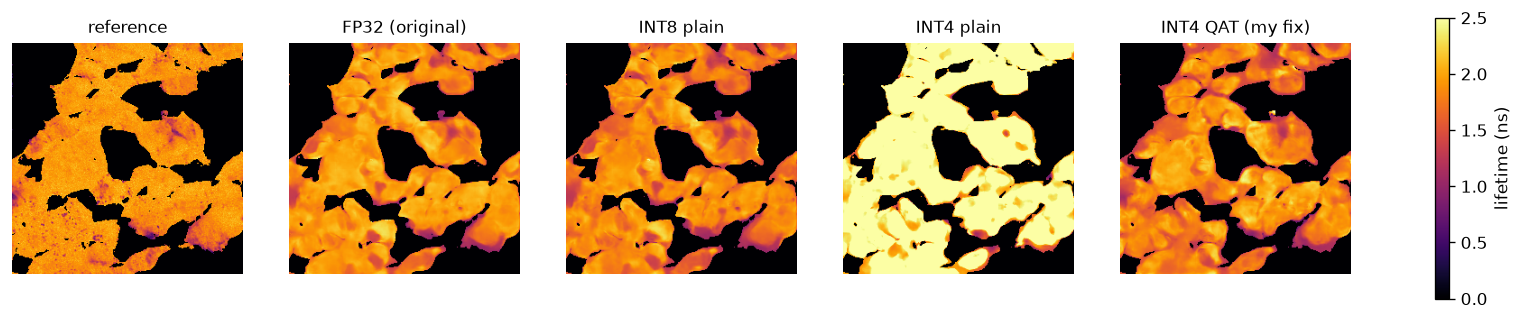

fig_qat_summary.png


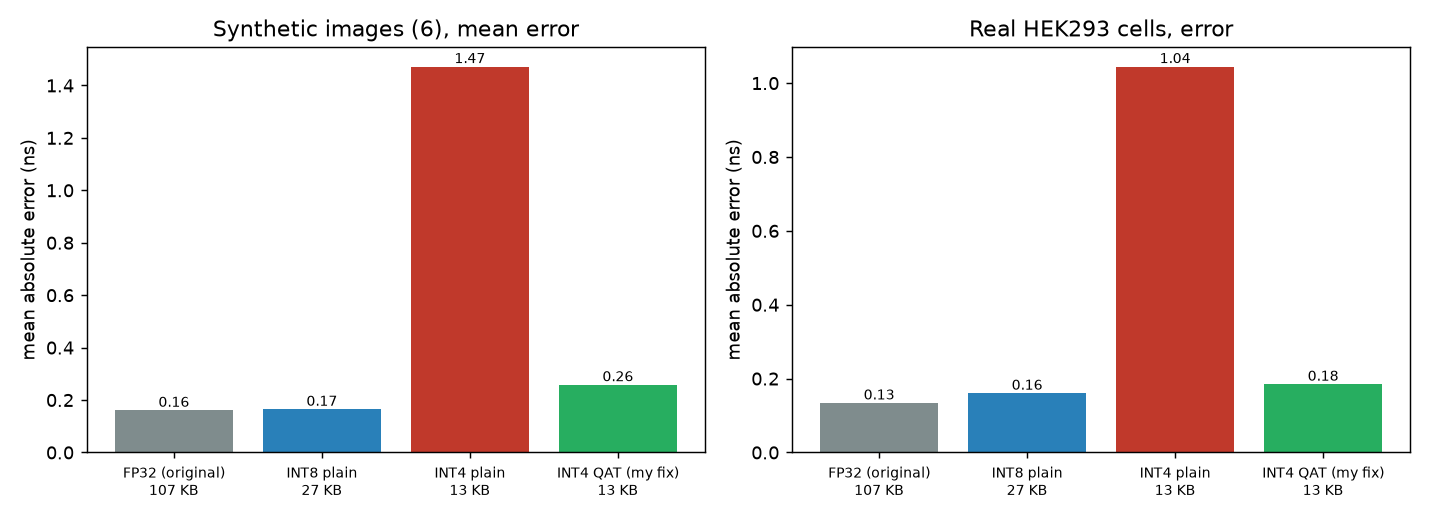

fig_synthetic3_qat.png


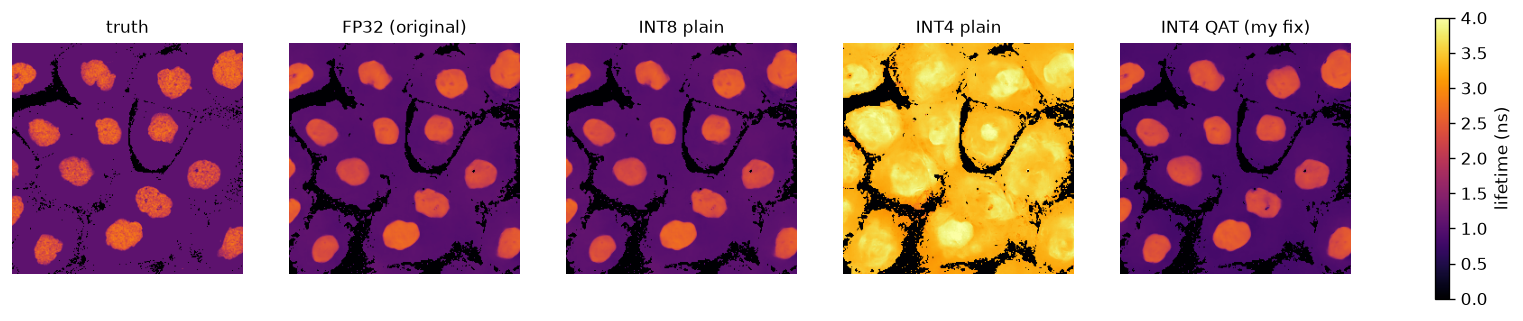

In [6]:
from IPython.display import Image, display
for f in sorted(glob.glob(os.path.join(OUT, "*.png"))):
    print(os.path.basename(f)); display(Image(filename=f, width=950))

## Part 2. Optimised 4 bit (V2, V3, V4)

**What this code does** (from the script `qat_4bit_v2.py`):

```
qat_4bit_v2.py  (Forhad: optimising the 4 bit LLE further)

Compared with qat_4bit.py (v1), three upgrades, tested step by step:
  V2 = v1 + knowledge distillation from Dr Li's FP32 network (teacher) + training data matched to his
       images (his exact Gaussian IRF for the general model, the MEASURED HEK293 IRF for the 1 to 3 ns
       model, photon counts like his 8x8 patches)
  V3 = V2 + learned step size quantisation (LSQ: each channel learns its best 4 bit scale)
  V4 = V3 + the tiny layers (two 128 weight input embeddings and the two smallest output layers,
       0.4% of all weights) kept at 8 bit
All variants are scored with the FULL FPFLI pipeline on his sample data, like v1.
Run with run_qat_v2_on_gpu.bat. Results: my_qat_v2_results/
```

### Setup: imports and settings

In [7]:
import os, json, time, copy, warnings, argparse, builtins
import numpy as np
import torch, torch.nn as nn
import torch.nn.utils.parametrize as P_
warnings.filterwarnings("ignore")
if not hasattr(torch, '_orig_load_saved'):     # patch torch.load only once per notebook
    torch._orig_load_saved = torch.load
    torch.load = lambda *a, **k: torch._orig_load_saved(*a, **{**k, "weights_only": False, "map_location": k.get("map_location", "cpu")})
import scipy.io as io, mat73
import matplotlib; matplotlib.use("Agg"); import matplotlib.pyplot as plt
from tau_net import tauNet
import Pred_local_lifetime as PLL
from Prep_exp_data import prep_exp_data
from Neural_implict_interploation import NIII_process

ap = argparse.ArgumentParser()
ap.add_argument("--n_train", type=int, default=400_000)
ap.add_argument("--epochs", type=int, default=20)
ap.add_argument("--smoke", action="store_true")
args = ap.parse_args([])
if args.smoke: args.n_train, args.epochs = 3000, 1
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEV, torch.cuda.get_device_name(0) if DEV.type == "cuda" else "", flush=True)
OUT = os.path.join(HERE, "my_qat_v2_results"); os.makedirs(OUT, exist_ok=True)
H, NB, MULT, PATCH = 0.039, 256, 0.039 * 100, 8
T0 = time.time()
irf_g = io.loadmat("sample_data/irf_gaussian.mat")["irf_gaussian"].astype("float32").ravel()
hek = io.loadmat("sample_data/hek_low.mat"); irf_hek = hek["irf"].astype("float32").ravel()
TINY = ["embd_decay", "embd_irf", "ponitconv2", "ponitconv3"]

Device: cuda NVIDIA GeForce RTX 3090


### Data matched to his images

In [8]:
def make_data(n, tau_lo, tau_hi, irf_base, rng):
    X, I, Y = [], [], []
    t = np.arange(1, NB + 1)
    for c in range(0, n, 20000):
        m = min(20000, n - c)
        two = rng.random(m) < 0.5
        t1 = rng.uniform(tau_lo, tau_hi, m); t2 = np.where(two, rng.uniform(tau_lo, tau_hi, m), t1)
        f1 = np.where(two, rng.uniform(0, 1, m), 1.0); f2 = 1 - f1
        yo = f1[:, None] * np.exp(-t[None] * H / t1[:, None]) + f2[:, None] * np.exp(-t[None] * H / t2[:, None])
        tau_ave = (f1 * t1 ** 2 + f2 * t2 ** 2) / (f1 * t1 + f2 * t2)
        # his IRF, shifted by up to half a bin and stretched by up to 10 percent
        sh = rng.uniform(-0.5, 0.5, m); st = rng.uniform(0.9, 1.1, m)
        pk = np.argmax(irf_base)
        src = pk + (t[None] - 1 - pk - sh[:, None]) / st[:, None]
        irf = np.stack([np.interp(s, np.arange(NB), irf_base, left=0, right=0) for s in src]).clip(0)
        irf = irf / irf.max(1, keepdims=True)
        lam = np.fft.irfft(np.fft.rfft(irf, 2 * NB) * np.fft.rfft(yo, 2 * NB), 2 * NB)[:, :NB].clip(0)
        N = 10 ** rng.uniform(np.log10(100), np.log10(3000), m)               # photons per 8x8 patch (his images: about 200 to 1300)
        y = rng.poisson(lam / lam.sum(1, keepdims=True) * N[:, None]).astype("float32")
        X.append(y / (y.max(1, keepdims=True) + 1e-8)); I.append(irf.astype("float32")); Y.append(tau_ave.astype("float32"))
    return np.concatenate(X), np.concatenate(I), np.concatenate(Y)

### Quantisers

In [9]:
class MaxQuant(nn.Module):                      # v1 style: scale = max|w| / qmax per channel
    def __init__(self, bits): super().__init__(); self.qmax = 2 ** (bits - 1) - 1
    def forward(self, w):
        f = w.reshape(w.shape[0], -1)
        s = f.abs().max(1, keepdim=True).values.clamp(min=1e-12) / self.qmax
        q = (torch.round(f / s).clamp(-self.qmax, self.qmax) * s).reshape(w.shape)
        return w + (q - w).detach()

class LSQQuant(nn.Module):                      # learned step size (Esser et al. 2020), per channel
    def __init__(self, w, bits):
        super().__init__(); self.qmax = 2 ** (bits - 1) - 1
        f = w.detach().reshape(w.shape[0], -1)
        self.s = nn.Parameter(f.abs().max(1, keepdim=True).values.clamp(min=1e-8) / self.qmax * 0.9)
        self.g = 1.0 / np.sqrt(f.shape[1] * self.qmax)
    def forward(self, w):
        f = w.reshape(w.shape[0], -1)
        s = self.s * self.g + (self.s - self.s * self.g).detach()           # gradient scaling
        v = (f / s).clamp(-self.qmax, self.qmax)
        q = (v + (torch.round(v) - v).detach()) * s
        return q.reshape(w.shape)

def convs(model):
    return [(n, m) for n, m in model.named_modules() if isinstance(m, nn.Conv1d)]

def bits_for(name, variant):
    return 8 if (variant == "V4" and any(name == t for t in TINY)) else 4

def train(weights, tau_lo, tau_hi, irf_base, variant, data):
    X, I, Y, Xv, Iv, Yv = data
    teacher = tauNet(); teacher.load_state_dict(torch.load(weights)); teacher.to(DEV).eval()
    model = tauNet(); model.load_state_dict(torch.load(weights)); model.to(DEV)
    for name, mod in convs(model):
        b = bits_for(name, variant)
        P_.register_parametrization(mod, "weight", MaxQuant(b) if variant == "V2" else LSQQuant(mod.weight, b))
    opt = torch.optim.AdamW(model.parameters(), lr=2e-4, weight_decay=1e-5)
    steps = args.epochs * (len(X) // 512)
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=5e-4, total_steps=max(1, steps), pct_start=0.15)
    Xt, It, Yt = torch.tensor(X), torch.tensor(I), torch.tensor(Y)
    def val(mm):
        mm.eval(); out = []
        with torch.no_grad():
            for i in range(0, len(Xv), 4096):
                out.append(mm(torch.tensor(Xv[i:i+4096]).unsqueeze(1).to(DEV), torch.tensor(Iv[i:i+4096]).unsqueeze(1).to(DEV)).cpu() * MULT)
        return float(np.median(np.abs(torch.cat(out).numpy() - Yv)))
    for ep in range(args.epochs):
        model.train(); perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt) - 511, 512):
            b = perm[i:i + 512]; x = Xt[b].unsqueeze(1).to(DEV); ir = It[b].unsqueeze(1).to(DEV)
            with torch.no_grad(): tt = teacher(x, ir) * MULT
            p = model(x, ir) * MULT
            loss = nn.functional.smooth_l1_loss(p, Yt[b].to(DEV), beta=0.1) + nn.functional.smooth_l1_loss(p, tt, beta=0.1)
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
        if (ep + 1) % 5 == 0 or ep == args.epochs - 1:
            print(f"  [{variant}] epoch {ep + 1}/{args.epochs} val median error {val(model):.4f} ns ({time.time() - T0:.0f} s)", flush=True)
    # recalibrate BatchNorm statistics with the final quantised weights
    for m in model.modules():
        if isinstance(m, nn.BatchNorm1d): m.reset_running_stats(); m.momentum = None
    model.train()
    with torch.no_grad():
        for i in range(0, min(len(Xt), 100_000), 1024):
            model(Xt[i:i+1024].unsqueeze(1).to(DEV), It[i:i+1024].unsqueeze(1).to(DEV))
    res = {"simulated_val_median_error_ns": val(model), "teacher_FP32_val_median_error_ns": val(teacher)}
    for _, mod in convs(model): P_.remove_parametrizations(mod, "weight", leave_parametrized=True)
    model.cpu()
    kbits = sum(m.weight.numel() * bits_for(n, variant) for n, m in convs(model))
    res["weight_KB"] = kbits / 8 / 1024
    res["max_levels_4bit_layers"] = max(len(torch.unique(m.weight[c])) for n, m in convs(model) if bits_for(n, variant) == 4 for c in range(m.weight.shape[0]))
    path = weights.replace(".pth", f"_{variant}.pth"); torch.save(model.state_dict(), path)
    print(f"  [{variant}] {json.dumps(res)}", flush=True)
    return path, res

### Pipeline scoring (same as v1)

In [10]:
_print = builtins.print
def quiet(f, *a, **k):
    builtins.print = lambda *x, **y: None
    try: return f(*a, **k)
    finally: builtins.print = _print
def run(hist, irf, path):
    inten = hist.sum(2); keep = inten > 3; hm = hist * keep[..., None]; mask = inten * keep
    lr = PLL.Pred_local_lifetime(hm, irf, scaling_ratio=PATCH, h=H, file_path=path).eval_local_tau()
    out = np.squeeze(quiet(NIII_process, prep_exp_data(mask, lr).prep_data(), ratio=PATCH), (0, 1)); out[out < 0] = 0
    return out, mask
def mae(p, g, m):
    k = (m > 0) & (g > 0); return float(np.mean(np.abs(p[k] - g[k])))
SYN = [(io.loadmat(f"sample_data/{s}.mat")) for s in (["3"] if args.smoke else ["1", "2", "3", "4", "5", "6"])]
HEKD = (hek["hist"].astype("float32"), hek["irf"].astype("float32"), mat73.loadmat("sample_data/hek_gt.mat")["tau_img_gt"].astype("float32"))
def score(pathA, pathB):
    syn = [mae(*run(d["Hist"].astype("float32"), irf_g[None], pathA), d["tau_gt"].astype("float32")) if False else None for d in []]
    syn = []
    for d in SYN:
        p, m = run(d["Hist"].astype("float32"), irf_g[None], pathA); syn.append(mae(p, d["tau_gt"].astype("float32"), m))
    p, m = run(HEKD[0].copy(), HEKD[1], pathB)
    return {"synthetic_per_image": syn, "synthetic_mean": float(np.mean(syn)), "HEK293": mae(p, HEKD[2], m)}

R = {"FP32 original": score("./model_parameters/LLE_parameter.pth", "./model_parameters/LLE_parameter_1_3ns.pth"),
     "V1 (previous QAT)": score("./model_parameters/LLE_parameter_QAT_INT4.pth", "./model_parameters/LLE_parameter_1_3ns_QAT_INT4.pth")}
for k in R: print(f"{k:28s} synthetic {R[k]['synthetic_mean']:.3f} ns  HEK293 {R[k]['HEK293']:.3f} ns", flush=True)
rng = np.random.default_rng(0)
if RETRAIN:
  dataA = (*make_data(args.n_train, 0.2, 4.5, irf_g, rng), *make_data(20000, 0.2, 4.5, irf_g, np.random.default_rng(1)))
  dataB = (*make_data(args.n_train, 1.0, 3.0, irf_hek, rng), *make_data(20000, 1.0, 3.0, irf_hek, np.random.default_rng(2)))
  print(f"data ready ({time.time() - T0:.0f} s)", flush=True)
for V in ["V2", "V3", "V4"]:
    print(f"=== {V} ===", flush=True)
    if RETRAIN:
        pA, rA = train("./model_parameters/LLE_parameter.pth", 0.2, 4.5, irf_g, V, dataA)
        pB, rB = train("./model_parameters/LLE_parameter_1_3ns.pth", 1.0, 3.0, irf_hek, V, dataB)
        R[V] = score(pA, pB); R[V]["train_general"] = rA; R[V]["train_1_3ns"] = rB; R[V]["weight_KB"] = rA["weight_KB"]
    else:
        pA, pB = f"./model_parameters/LLE_parameter_{V}.pth", f"./model_parameters/LLE_parameter_1_3ns_{V}.pth"
        R[V] = score(pA, pB)
        R[V]["weight_KB"] = sum(m.weight.numel() * bits_for(n, V) for n, m in convs(tauNet())) / 8 / 1024
    print(f"{V:28s} synthetic {R[V]['synthetic_mean']:.3f} ns  HEK293 {R[V]['HEK293']:.3f} ns  ({R[V]['weight_KB']:.1f} KB)", flush=True)
    json.dump(R, open(f"{OUT}/qat_v2_results.json", "w"), indent=2)

names = ["FP32 original", "V1 (previous QAT)", "V2", "V3", "V4"]
labels = ["FP32\n107 KB", "4 bit v1\n13 KB", "4 bit v2\n+distill, matched data", "4 bit v3\n+learned scales", f"4 bit v4\n+tiny layers 8 bit\n{R['V4']['weight_KB']:.1f} KB"]
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for a, key, t in [(ax[0], "synthetic_mean", "His 6 synthetic images, mean error"), (ax[1], "HEK293", "Real HEK293 cells, error")]:
    v = [R[n][key] for n in names]
    bars = a.bar(range(len(v)), v, color=["#7f8c8d", "#c0392b", "#e67e22", "#2980b9", "#27ae60"])
    a.set_xticks(range(len(v))); a.set_xticklabels(labels, fontsize=7.5); a.set_ylabel("mean absolute error (ns)"); a.set_title(t)
    for b_, x in zip(bars, v): a.text(b_.get_x() + b_.get_width() / 2, x, f"{x:.3f}", ha="center", va="bottom", fontsize=8)
fig.tight_layout(); fig.savefig(f"{OUT}/fig_qat_v2_summary.png", dpi=130); plt.close(fig)
print(f"ALL DONE ({time.time() - T0:.0f} s)", flush=True)

FP32 original                synthetic 0.161 ns  HEK293 0.134 ns
V1 (previous QAT)            synthetic 0.259 ns  HEK293 0.185 ns
=== V2 ===
V2                           synthetic 0.165 ns  HEK293 0.159 ns  (13.3 KB)
=== V3 ===
V3                           synthetic 0.167 ns  HEK293 0.150 ns  (13.3 KB)
=== V4 ===
V4                           synthetic 0.167 ns  HEK293 0.142 ns  (13.5 KB)
ALL DONE (11 s)


### Figures from Part 2

fig_qat_v2_summary.png


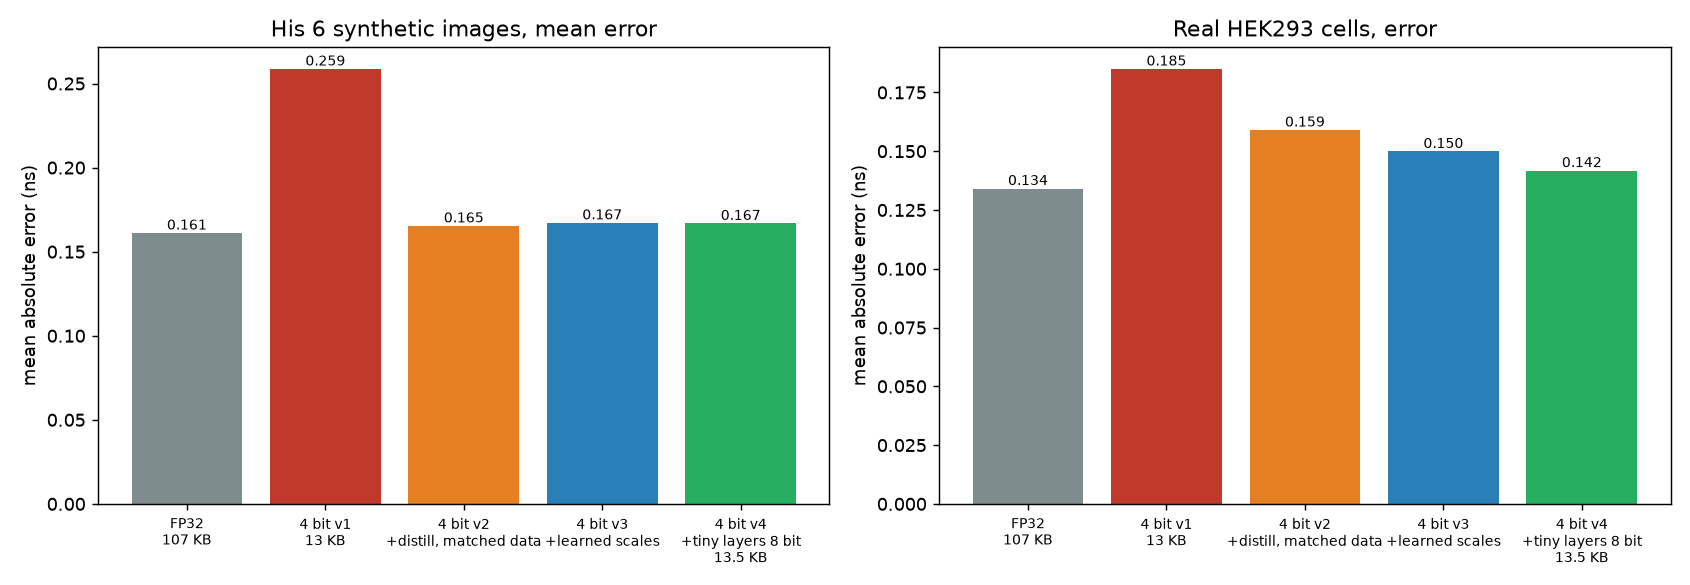

In [11]:
from IPython.display import Image, display
for f in sorted(glob.glob(os.path.join(OUT, "*.png"))):
    print(os.path.basename(f)); display(Image(filename=f, width=950))